# Homework #3

## Dataset

In this homework, we will use Course Management Platform lead scoring dataset. Download it from [here](https://raw.githubusercontent.com/alexeygrigorev/datasets/master/course_lead_scoring.csv).

In [54]:
import numpy as np
import pandas as pd

from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mutual_info_score, accuracy_score

import matplotlib.pyplot as plt
import seaborn as sns

In [55]:
data = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')
data.shape

(5000, 9)

In [56]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


In [57]:
data.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [58]:
data.nunique()

lead_source                    5
industry                       6
employment_status              4
location                       5
annual_income               4313
number_of_courses_viewed       7
interaction_count             14
lead_score                    99
converted                      2
dtype: int64

In [59]:
data.isna().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

## Question 1

What is the most frequent observation (mode) for the column industry?

In [60]:
data.describe(include=["str"])

,lead_source,industry,employment_status,location
count,4852,4760,4806,4792
unique,5,6,4,5
top,organic_search,technology,employed,north_america
freq,1251,1173,2633,1371


In [61]:
data['industry'].value_counts()

industry
technology       1173
retail            925
healthcare        840
finance           720
education         639
manufacturing     463
Name: count, dtype: int64

## Question 2

* Create the correlation matrix for the numerical features of your dataset
* In a correlation matrix, you compute the correlation coefficient between every pair of features in the dataset
* What are the two features that have the biggest correlation in this dataset?

In [62]:
data_numeric = data.copy()
data_numeric = data.drop(
    ['lead_source', 'industry', 'employment_status', 'location', 'converted'],
    axis=1
)
data_numeric.describe()

,annual_income,number_of_courses_viewed,interaction_count,lead_score
count,4631.000000,5000.000000,5000.000000,4965.000000
mean,54533.212049,2.089400,4.472600,0.494767
std,21245.661710,1.188987,2.435906,0.199431
min,12000.000000,0.000000,0.000000,0.010000
25%,40458.500000,1.000000,3.000000,0.360000
50%,55051.000000,2.000000,4.000000,0.490000
75%,71252.500000,3.000000,6.000000,0.630000
max,109886.000000,6.000000,13.000000,0.990000


In [63]:
data_numeric.corr()

,annual_income,number_of_courses_viewed,interaction_count,lead_score
annual_income,1.000000,0.137542,0.106375,0.231396
number_of_courses_viewed,0.137542,1.000000,0.721609,0.769352
interaction_count,0.106375,0.721609,1.000000,0.928712
lead_score,0.231396,0.769352,0.928712,1.000000


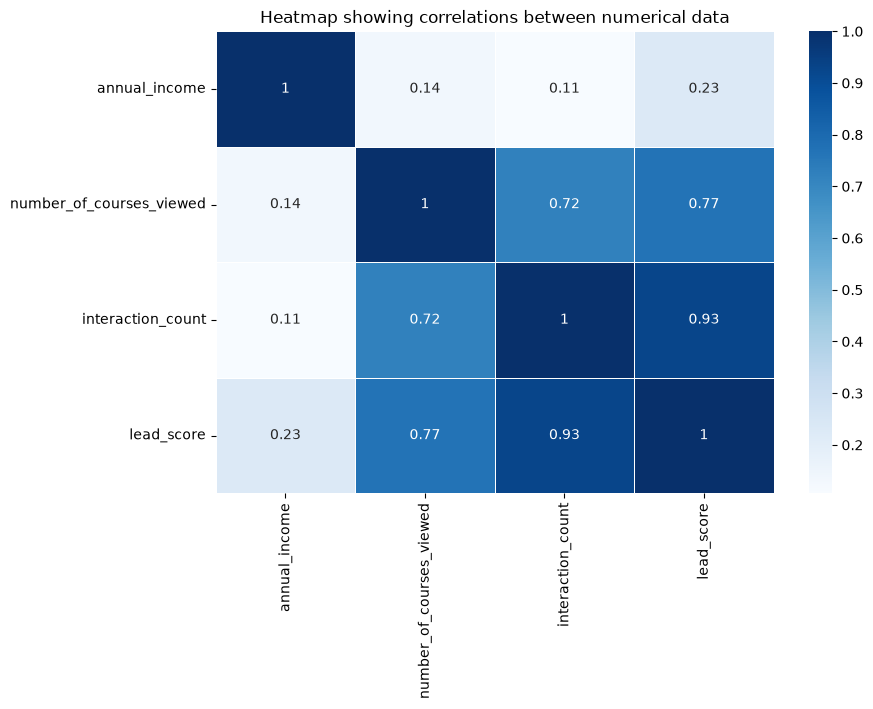

In [64]:
plt.figure(figsize=(9, 6))
sns.heatmap(data_numeric.corr(),annot=True,linewidths=.5, cmap="Blues")
plt.title('Heatmap showing correlations between numerical data')
plt.show()

In [65]:
data_numeric.corr().unstack().sort_values(ascending=False)

annual_income             annual_income               1.000000
number_of_courses_viewed  number_of_courses_viewed    1.000000
lead_score                lead_score                  1.000000
interaction_count         interaction_count           1.000000
                          lead_score                  0.928712
lead_score                interaction_count           0.928712
number_of_courses_viewed  lead_score                  0.769352
lead_score                number_of_courses_viewed    0.769352
number_of_courses_viewed  interaction_count           0.721609
interaction_count         number_of_courses_viewed    0.721609
lead_score                annual_income               0.231396
annual_income             lead_score                  0.231396
                          number_of_courses_viewed    0.137542
number_of_courses_viewed  annual_income               0.137542
annual_income             interaction_count           0.106375
interaction_count         annual_income               0

`number_of_courses_viewed` and `interaction_count`

## Split the data

* Split your data in train/val/test sets with 60%/20%/20% distribution
* Use Scikit-Learn for that (the `train_test_split` function) and set the seed to `42`
* Make sure that the target value `y` is not in your dataframe

In [66]:
SEED = 42

In [67]:
df = data
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)

assert len(df) == len(df_train) + len(df_val) + len(df_test)

In [68]:
len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

In [69]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [70]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

df_train = df_train.drop(columns='converted')
df_val = df_val.drop(columns='converted')
df_test = df_test.drop(columns='converted')

assert 'converted' not in df_train.columns
assert 'converted' not in df_val.columns
assert 'converted' not in df_test.columns

## Question 3

* Calculate the mutual information score between `y` and other categorical variables in the dataset. Use the training set only
* Round the scores to 2 decimals using `round(score, 2)`
* Which of these variables has the biggest score?

In [71]:
def calculate_mi(series):
    return mutual_info_score(series, y_train)

In [72]:
cat = ['lead_source', 'industry', 'employment_status', 'location']
numeric = ['number_of_courses_viewed', 'annual_income', 'interaction_count',
       'lead_score']

### Data preparation

In [73]:
features = cat + numeric
missing_features = data[features].isna().sum()
missing_features[missing_features > 0]

lead_source          148
industry             240
employment_status    194
location             208
annual_income        369
lead_score            35
dtype: int64

In [74]:
for df in (df_train, df_val, df_test):
    df[cat] = df[cat].fillna('NA')
    df[numeric] = df[numeric].fillna(0.0)

    assert not df[features].isna().any().any()

In [75]:
df_mi = df_train[cat].apply(calculate_mi)
df_mi = df_mi.sort_values(ascending=False).to_frame(name='MI')
df_mi

,MI
lead_source,0.034346
employment_status,0.018966
industry,0.001995
location,0.001043


`lead_source` has the biggest score.

In [76]:
assert 'converted' not in df_train.columns
assert 'converted' not in df_val.columns
assert 'converted' not in df_test.columns

## Question 4

* Now let's train a logistic regression
* Remember that we have several categorical variables in the dataset. Include them using one-hot encoding
* Fit the model on the training dataset:
    * To make sure the results are reproducible across different versions of Scikit-Learn, fit the model with these parameters:

```
model = LogisticRegression(
    solver='liblinear',
    C=1.0,
    max_iter=1000,
    random_state=42
)
```
* Calculate the accuracy on the validation dataset and round it to 2 decimal digits

In [77]:
dv = DictVectorizer(sparse=False)
train_dict = df_train.to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

In [78]:
model = LogisticRegression(
    solver='liblinear',
    C=1.0,
    max_iter=1000,
    random_state=42
)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l

In [79]:
val_dict = df_val.to_dict(orient='records')
X_val = dv.transform(val_dict)

y_pred = model.predict(X_val)

In [80]:
original_score = accuracy_score(y_val, y_pred)
original_score

0.645

In [81]:
accuracy = np.round(original_score, 2)
print(f'Accuracy = {accuracy}')

Accuracy = 0.64


## Question 5

* Let's find the least useful feature using the _feature elimination_ technique
* Train a model with all these features (using the same parameters as in Q4)
* Now exclude each feature from this set and train a model without it. Record the accuracy for each model
* For each feature, calculate the difference between the original accuracy and the accuracy without the feature
* Which of following feature has the smallest difference?
    - 'industry',
    - 'employment_status',
    - 'lead_score'
* Round your answer to 2 decimal digits
    
> **note:** the difference doesn't have to be positive

In [82]:
features = df_train.columns.to_list()
eliminate = [
 'industry',
 'employment_status',
 'lead_score']

In [83]:
scores = pd.DataFrame(columns=['eliminated_feature', 'accuracy', 'difference'])
for feature in eliminate:
    subset = features.copy()
    subset.remove(feature)
    
    dv = DictVectorizer(sparse=False)
    train_dict = df_train[subset].to_dict(orient='records')
    X_train = dv.fit_transform(train_dict)

    model = LogisticRegression(
        solver='liblinear',
        C=1,
        max_iter=1000,
        random_state=42
    )
    model.fit(X_train, y_train)
    
    val_dict = df_val[subset].to_dict(orient='records')
    X_val = dv.transform(val_dict)
    
    y_pred = model.predict(X_val)
    score = accuracy_score(y_val, y_pred)
    
    scores.loc[len(scores)] = [feature, score, original_score - score]

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preproc

In [84]:
scores

,eliminated_feature,accuracy,difference
0,industry,0.728,-0.083
1,employment_status,0.722,-0.077
2,lead_score,0.724,-0.079


In [85]:
scores[scores.index == scores.difference.idxmin()]

,eliminated_feature,accuracy,difference
0,industry,0.728,-0.083


industry (closely followed by employment_status)

## Question 6

* Now let's train a regularized logistic regression
* Let's try the following values of the parameter `C`: `[0, 0.01, 0.1, 1, 10]`
* Train models using all the features as in Q4
* Calculate the accuracy on the validation dataset and round it to 3 decimal digits
* Which of these `C` leads to the best accuracy on the validation set?
> **note:** If there are multiple options, select the smallest `C`.

In [86]:
y_train.shape, y_val.shape

((3000,), (1000,))

In [87]:
dv = DictVectorizer(sparse=False)
train_dict = df_train.to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = df_val.to_dict(orient='records')
X_val = dv.transform(val_dict)

In [88]:
scores = {}
for C in [0.01, 0.1, 1, 10, 100]:
    model = LogisticRegression(
        solver='liblinear',
        max_iter=1000,
        C=C,
        random_state=SEED
    )
    model.fit(X_train, y_train)
    
    y_pred = model.predict(X_val)
    
    score = accuracy_score(y_val, y_pred)
    scores[C] = round(score, 3)
    print(f'C = {C}:\t Accuracy = {score}')

C = 0.01:	 Accuracy = 0.713


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C = 0.1:	 Accuracy = 0.73


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C = 1:	 Accuracy = 0.722


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C = 10:	 Accuracy = 0.723
C = 100:	 Accuracy = 0.724


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [89]:
scores

{0.01: 0.713, 0.1: 0.73, 1: 0.722, 10: 0.723, 100: 0.724}

In [90]:
print(f'The best `C` is {max(scores, key=scores.get)}.')

The best `C` is 0.1.
